# Fine-tuning GPT-2 - detect Spam messages


### Load the SMS Spam dataset


In [1]:
from datasets import load_dataset

sms_spam_dataset = load_dataset("ucirvine/sms_spam")
print(sms_spam_dataset)

DatasetDict({
    train: Dataset({
        features: ['sms', 'label'],
        num_rows: 5574
    })
})


In [2]:
sms_spam_dataset["train"][0]

{'sms': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n',
 'label': 0}

### Train-Test Split


In [3]:
train_test_split = 0.9

shuffled_dataset = sms_spam_dataset["train"].shuffle()
train_len = int(len(shuffled_dataset) * train_test_split)

training_data = shuffled_dataset[:train_len]
validation_data = shuffled_dataset[train_len:]

In [4]:
def get_spam_non_spam_count(data):
    spam = 0
    for label in data["label"]:
        if label == 1:
            spam += 1
    print(f"Spam: {spam}, Non Spam: {len(data['label']) - spam}")
    print(f"Spam: {(spam/len(data['label']))*100}%")


print(f"Training data size: {len(training_data['sms'])}")
get_spam_non_spam_count(training_data)
print(f"Validation data size: {len(validation_data['sms'])}")
get_spam_non_spam_count(validation_data)

Training data size: 5016
Spam: 687, Non Spam: 4329
Spam: 13.696172248803828%
Validation data size: 558
Spam: 60, Non Spam: 498
Spam: 10.75268817204301%


## Tokenize the dataset


In [5]:
from transformers import GPT2Tokenizer

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

In [6]:
def tokenize_dataset(dataset):
    tokenized_dataset = []

    for message, label in zip(dataset["sms"], dataset["label"]):
        encoded_ids = tokenizer.encode(message)
        tokenized_dataset.append((encoded_ids, label))

    return tokenized_dataset

In [7]:
tokenized_training_dataset = tokenize_dataset(training_data)
tokenized_validation_dataset = tokenize_dataset(validation_data)

print(tokenized_training_dataset[0])
print(tokenizer.decode(tokenized_training_dataset[0][0]))

([3666, 2156, 994, 304, 6766, 2407, 3223, 300, 13481, 986, 1002, 43079, 788, 1392, 12226, 407, 362, 1057, 1541, 46048, 986, 679, 68, 986, 198], 0)
My house here e sky quite dark liao... If raining then got excuse not 2 run already rite... Hee...



## Load GPT-2 Model


In [8]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cuda'

In [9]:
from transformers import GPT2Model

model = GPT2Model.from_pretrained("gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [10]:
model

GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-11): 12 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
)

We can see the final (Layer-Norm) layer has an out dimension of **768**. We need to add an additional custom layer after the LayerNorm layer which will classify the input text as **spam (0)** or **not-spam (1)**.

Before that let's generate some content from the GPT-2 model.


In [11]:
from transformers import pipeline

generator = pipeline("text-generation", model="gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [12]:
generator("kill him", max_length=30, num_return_sequences=1)

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "kill him. He's the kind of guy that you would want to be around during the playoffs, and he's got a good sense of humor.\n\nI wish he would be all that good.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want to see.\n\nThat's what I want"}]

In [26]:
from torch import nn
import torch


class GptSpamClass(nn.Module):
    def __init__(self):
        super(GptSpamClass, self).__init__()

        self.gpt2 = GPT2Model.from_pretrained("gpt2")  # out dimension = 768
        self.out_layer = nn.Linear(768, 2)  # out dimension = 2

    def forward(self, input_ids):
        outputs = self.gpt2.forward(input_ids=input_ids)
        hidden_states = outputs.last_hidden_state

        # Because GPT-2 is a causal (left-to-right) model, the meaningful context
        # for the whole sentence accumulates at the VERY LAST token.
        # So, we usually extract just the last token's hidden state to pass to our new layer.

        # Grab the last token's representation for each sequence in the batch
        # (Assuming you are padding appropriately)
        last_token_states = hidden_states[:, -1, :]  # B, 1, 768

        final_output = self.out_layer(last_token_states)  # B, 1, 2

        return final_output

    def predict(self, sms: str):
        self.eval() 
        device = next(self.parameters()).device

        encoded_ids = tokenizer.encode(sms)
        encoded_ids = torch.tensor([encoded_ids], device=device)

        logits = self.forward(encoded_ids)
        predicted_label = torch.argmax(logits, dim=-1)

        verdict = "Not Spam" if predicted_label == 0 else "Spam"

        return verdict

In [27]:
gpt2_spam_model = GptSpamClass().to(DEVICE)
gpt2_spam_model

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GptSpamClass(
  (gpt2): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (out_layer): Linear(in_features=768, out_features=2, bias=True)
)

In [28]:
f"{(sum(parameter.numel() for parameter in gpt2_spam_model.parameters()) / 1e6):.2f} million parameters"

'124.44 million parameters'

## Fine-tune


In [29]:
# Feeze the entire model
for parameter in gpt2_spam_model.parameters():
    parameter.requires_grad = False

# Making the last attention block trainable
for parameter in gpt2_spam_model.gpt2.h[-1].parameters():
    parameter.requires_grad = True

# Making the last output layer trainable as well
for parameter in gpt2_spam_model.out_layer.parameters():
    parameter.requires_grad = True

In [30]:
sum(parameter.numel() for parameter in gpt2_spam_model.out_layer.parameters()) + sum(
    parameter.numel() for parameter in gpt2_spam_model.gpt2.h[-1].parameters()
)

7089410

In [31]:
def get_mean(losses):
    sum = 0.0
    for loss in losses:
        sum += loss.item()
    return sum / len(losses)

In [32]:
from torch.nn.utils.rnn import pad_sequence

gpt2_spam_model.train()

epochs = 2
batch_size = 8
eval_intervals = batch_size * 50
losses = []
overall_losses = []

optimizer = torch.optim.AdamW(gpt2_spam_model.parameters(), lr=5e-5, weight_decay=0.1)

for epoch in range(epochs):
    Xb = []
    Yb = []
    print(f"Epoch: {epoch+1}")

    for i, row in enumerate(tokenized_training_dataset):
        encoded_msg = row[0]
        label = row[1]
        Xb.append(torch.tensor(encoded_msg))
        Yb.append(torch.tensor(label))

        if (len(Xb) % batch_size) == 0:
            optimizer.zero_grad()

            padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(
                DEVICE
            )
            labels = torch.stack(Yb).to(DEVICE)
            logits = gpt2_spam_model(padded_batch)
            loss = torch.nn.functional.cross_entropy(logits, labels)

            losses.append(loss)
            overall_losses.append(loss)

            loss.backward()
            optimizer.step()
            Xb = []
            Yb = []

            if (i + 1) % eval_intervals == 0:
                print(f"Interval: {i+1}, Loss: {get_mean(losses)}")
                losses = []

    if len(Xb) > 0:
        optimizer.zero_grad()

        padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(DEVICE)
        labels = torch.stack(Yb).to(DEVICE)
        logits = gpt2_spam_model(padded_batch)
        loss = torch.nn.functional.cross_entropy(logits, labels)

        losses.append(loss)
        overall_losses.append(loss)
        
        loss.backward()
        optimizer.step()

Epoch: 1
Interval: 400, Loss: 0.5441781158745289
Interval: 800, Loss: 0.3356430593132973
Interval: 1200, Loss: 0.2590628528594971
Interval: 1600, Loss: 0.20636598497629166
Interval: 2000, Loss: 0.14346891053020955
Interval: 2400, Loss: 0.12096297273412347
Interval: 2800, Loss: 0.10194881599396467
Interval: 3200, Loss: 0.06444716763682663
Interval: 3600, Loss: 0.07078117952682078
Interval: 4000, Loss: 0.07388304613763466
Interval: 4400, Loss: 0.03980101947672665
Interval: 4800, Loss: 0.03755207975395024
Epoch: 2
Interval: 400, Loss: 0.04127826479296865
Interval: 800, Loss: 0.037214706866070625
Interval: 1200, Loss: 0.041731933413539084
Interval: 1600, Loss: 0.022515966910286806
Interval: 2000, Loss: 0.0520344082696829
Interval: 2400, Loss: 0.05004205575212836
Interval: 2800, Loss: 0.065250556783285
Interval: 3200, Loss: 0.04300912639359012
Interval: 3600, Loss: 0.04813332346500829
Interval: 4000, Loss: 0.04093599864863791
Interval: 4400, Loss: 0.014242213550023735
Interval: 4800, Loss: 

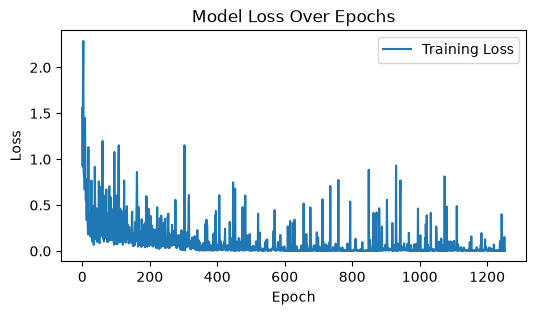

In [33]:
import matplotlib.pyplot as plt


def plot_loss_curve(losses):
    loss_list = [loss.item() for loss in losses]

    # Plot the loss curve
    plt.figure(figsize=(6, 3))  # Optional: adjust figure size
    plt.plot(loss_list, label="Training Loss")

    # Add titles and labels
    plt.title("Model Loss Over Epochs")
    plt.ylabel("Loss")
    plt.xlabel("Epoch")
    plt.legend()  # Show the legend

    # Display the plot
    plt.show()


plot_loss_curve(overall_losses)

In [34]:
def get_dataset_accuracy(model, tokenized_dataset, log_interval):

    model.eval()
    device = next(model.parameters()).device

    encoded_messages = [row[0] for row in tokenized_dataset]
    labels = [row[1] for row in tokenized_dataset]
    processed = 0
    correct_predictions = 0

    for encoded_message, label in zip(encoded_messages, labels):
        with torch.no_grad():
            encoded_message = torch.tensor(encoded_message).view(
                1, len(encoded_message)
            )
            logits = model(torch.tensor(encoded_message).to(device))
        predicted_label = torch.argmax(logits, dim=-1)

        if predicted_label == label:
            correct_predictions += 1

        if processed % log_interval == 0:
            print(f"Processed: {processed}")
        processed += 1

    print(f"{correct_predictions} / {len(encoded_messages)}")
    accuracy = (correct_predictions / len(encoded_messages)) * 100.0
    print(f"Accuracy: {accuracy}")

    return accuracy

In [35]:
train_accuracy = get_dataset_accuracy(
    gpt2_spam_model, tokenized_training_dataset, log_interval=500
)
print(f"Training dataset accuracy: {train_accuracy}")

C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 0
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
4893 / 5016
Accuracy: 97.54784688995215
Training dataset accuracy: 97.54784688995215


In [36]:
validation_accuracy = get_dataset_accuracy(
    gpt2_spam_model, tokenized_validation_dataset, log_interval=100
)
print(f"Validation dataset accuracy: {validation_accuracy}")

Processed: 0

C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))



Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
540 / 558
Accuracy: 96.7741935483871
Validation dataset accuracy: 96.7741935483871


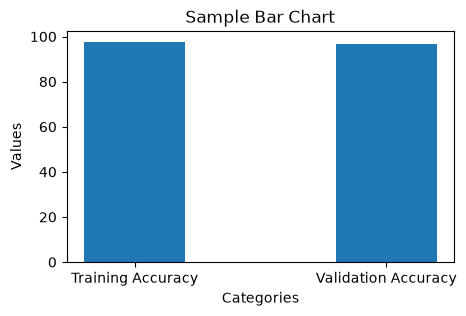

In [37]:
import numpy as np


def plot_bar_chart(training_accuracy, validation_accuracy):
    # Data for the bar chart
    categories = np.array(["Training Accuracy", "Validation Accuracy"])
    values = np.array([training_accuracy, validation_accuracy])

    # Create the bar chart
    plt.figure(figsize=(5, 3))
    plt.bar(categories, values, width=0.4)

    # Add labels and a title
    plt.xlabel("Categories")
    plt.ylabel("Values")
    plt.title("Sample Bar Chart")

    # Display the chart
    plt.show()


plot_bar_chart(train_accuracy, validation_accuracy)

In [38]:
messages = [
    "Last a chance to win 1 Lakh, call at 5676 now!",
    "How are you doing?",
    "Get home loan at low rates now, click to this link http://win/ to know more",
    "Reaching your location in 5 minutes",
]

for message in messages:
    prediction = gpt2_spam_model.predict(message)
    print(f"{message} -> {prediction}")

Last a chance to win 1 Lakh, call at 5676 now! -> Spam
How are you doing? -> Not Spam
Get home loan at low rates now, click to this link http://win/ to know more -> Not Spam
Reaching your location in 5 minutes -> Not Spam


## Using BERT


In [39]:
from transformers import BertTokenizer

# Replace GPT2Tokenizer with BertTokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# Your tokenize_dataset function remains exactly the same!
tokenized_training_dataset = tokenize_dataset(training_data)
tokenized_validation_dataset = tokenize_dataset(validation_data)

In [40]:
from transformers import BertModel
from torch import nn
import torch


class BertSpamClass(nn.Module):
    def __init__(self):
        super(BertSpamClass, self).__init__()

        # Load BERT instead of GPT-2
        self.bert = BertModel.from_pretrained(
            "bert-base-uncased"
        )  # out dimension = 768
        self.out_layer = nn.Linear(768, 2)  # out dimension = 2

    def forward(self, input_ids):
        # Dynamically create attention mask (1 for real tokens, 0 for padding)
        # This allows your existing training loop using pad_sequence to work perfectly.
        attention_mask = (input_ids != 0).long()

        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state

        # CRITICAL CHANGE: BERT uses the [CLS] token (the very first token at index 0)
        # to represent the context of the whole sequence, not the last token.
        cls_token_states = hidden_states[:, 0, :]  # B, 768

        final_output = self.out_layer(cls_token_states)  # B, 2

        return final_output

    def predict(self, sms: str):
        self.eval() 
        device = next(self.parameters()).device

        encoded_ids = tokenizer.encode(sms)
        encoded_ids = torch.tensor([encoded_ids], device=device)

        logits = self.forward(encoded_ids)
        predicted_label = torch.argmax(logits, dim=-1)

        verdict = "Not Spam" if predicted_label == 0 else "Spam"

        return verdict

In [41]:
bert_spam_ham_model = BertSpamClass().to(DEVICE)
bert_spam_ham_model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertSpamClass(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elem

In [42]:
f"{(sum(parameter.numel() for parameter in bert_spam_ham_model.parameters()) / 1e6):.2f} million parameters"

'109.48 million parameters'

## Fine Tune BERT


In [43]:
# Freeze the entire model
for parameter in bert_spam_ham_model.parameters():
    parameter.requires_grad = False

# CRITICAL CHANGE: Accessing the last attention block in BERT
for parameter in bert_spam_ham_model.bert.encoder.layer[-1].parameters():
    parameter.requires_grad = True

# Making the last output layer trainable as well
for parameter in bert_spam_ham_model.out_layer.parameters():
    parameter.requires_grad = True

In [44]:
from torch.nn.utils.rnn import pad_sequence

bert_spam_ham_model.train()

epochs = 2
batch_size = 8
eval_intervals = batch_size * 50
losses = []
overall_losses = []

optimizer = torch.optim.AdamW(
    bert_spam_ham_model.parameters(), lr=5e-5, weight_decay=0.1
)

for epoch in range(epochs):
    Xb = []
    Yb = []
    print(f"Epoch: {epoch+1}")

    for i, row in enumerate(tokenized_training_dataset):
        encoded_msg = row[0]
        label = row[1]
        Xb.append(torch.tensor(encoded_msg))
        Yb.append(torch.tensor(label))

        if (len(Xb) % batch_size) == 0:
            optimizer.zero_grad()

            padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(
                DEVICE
            )
            labels = torch.stack(Yb).to(DEVICE)
            logits = bert_spam_ham_model(padded_batch)
            loss = torch.nn.functional.cross_entropy(logits, labels)

            losses.append(loss)
            overall_losses.append(loss)

            loss.backward()
            optimizer.step()
            Xb = []
            Yb = []

            if (i + 1) % eval_intervals == 0:
                print(f"Interval: {i+1}, Loss: {get_mean(losses)}")
                losses = []

    if len(Xb) > 0:
        optimizer.zero_grad()

        padded_batch = pad_sequence(Xb, batch_first=True, padding_value=0).to(DEVICE)
        labels = torch.stack(Yb).to(DEVICE)
        logits = bert_spam_ham_model(padded_batch)
        loss = torch.nn.functional.cross_entropy(logits, torch.tensor(Yb))

        losses.append(loss)
        overall_losses.append(loss)

        loss.backward()
        optimizer.step()

Epoch: 1
Interval: 400, Loss: 0.22437114292755722
Interval: 800, Loss: 0.06379959852900356
Interval: 1200, Loss: 0.05628503468818963
Interval: 1600, Loss: 0.02365140957874246
Interval: 2000, Loss: 0.04911001578788273
Interval: 2400, Loss: 0.04121296267025173
Interval: 2800, Loss: 0.07628184924600646
Interval: 3200, Loss: 0.044553607772104445
Interval: 3600, Loss: 0.04265335410134867
Interval: 4000, Loss: 0.05396640096325427
Interval: 4400, Loss: 0.030762491868808865
Interval: 4800, Loss: 0.007893633223720825
Epoch: 2
Interval: 400, Loss: 0.021803283534207768
Interval: 800, Loss: 0.0340012815274531
Interval: 1200, Loss: 0.02295535528799519
Interval: 1600, Loss: 0.011699619584251196
Interval: 2000, Loss: 0.00838878320675576
Interval: 2400, Loss: 0.016665848981647288
Interval: 2800, Loss: 0.06440281577859423
Interval: 3200, Loss: 0.02465698009298649
Interval: 3600, Loss: 0.02055973970098421
Interval: 4000, Loss: 0.037814955450885465
Interval: 4400, Loss: 0.011546182043093722
Interval: 480

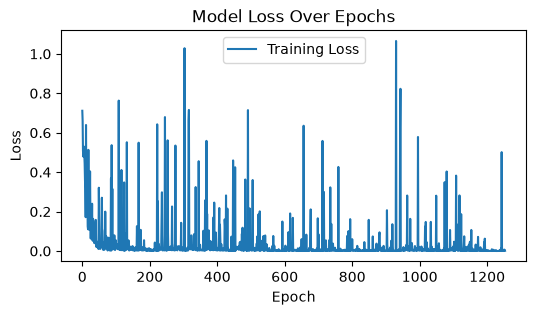

In [45]:
plot_loss_curve(overall_losses)

In [46]:
train_accuracy = get_dataset_accuracy(
    bert_spam_ham_model, tokenized_training_dataset, log_interval=500
)
print(f"Training dataset accuracy: {train_accuracy}")

C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 0
Processed: 500
Processed: 1000
Processed: 1500
Processed: 2000
Processed: 2500
Processed: 3000
Processed: 3500
Processed: 4000
Processed: 4500
Processed: 5000
4993 / 5016
Accuracy: 99.5414673046252
Training dataset accuracy: 99.5414673046252


In [47]:
validation_accuracy = get_dataset_accuracy(
    bert_spam_ham_model, tokenized_validation_dataset, log_interval=100
)
print(f"Validation dataset accuracy: {validation_accuracy}")

Processed: 0


C:\Users\USER\AppData\Local\Temp\ipykernel_32084\283834730.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  logits = model(torch.tensor(encoded_message).to(device))


Processed: 100
Processed: 200
Processed: 300
Processed: 400
Processed: 500
555 / 558
Accuracy: 99.46236559139786
Validation dataset accuracy: 99.46236559139786


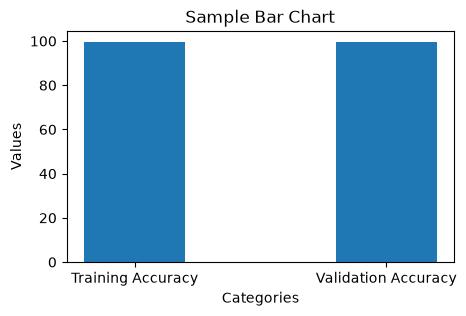

In [48]:
plot_bar_chart(train_accuracy, validation_accuracy)

In [49]:
messages = [
    "Last a chance to win 1 Lakh, call at 5676 now!",
    "How are you doing?",
    "Get home loan at low rates now, click to this link http://win/ to know more",
    "Reaching your location in 5 minutes",
]

for message in messages:
    prediction = bert_spam_ham_model.predict(message)
    print(f"{message} -> {prediction}")

Last a chance to win 1 Lakh, call at 5676 now! -> Spam
How are you doing? -> Not Spam
Get home loan at low rates now, click to this link http://win/ to know more -> Spam
Reaching your location in 5 minutes -> Not Spam
